# Does SAM's calibration gain track overfitting? (Fashion-MNIST, small CNN, SGD vs SAM)

**Question.** Does Sharpness-Aware Minimization (SAM) improve test accuracy and calibration over plain SGD for a small
convolutional network on Fashion-MNIST, and does any calibration gain follow the overfitting (training loss and sharpness) of the two optimisers?

**Model and data.** A small CNN (two conv blocks with batch norm and 2x2 max pooling, then two linear layers). Both optimisers
share the initialisation and data order for each seed. Configuration: lr 0.03, momentum 0.9, weight decay 5e-4, batch 128,
cosine schedule, SAM rho 0.1.

**What you will see.** The script trains SGD and SAM, logs per-epoch training loss and validation calibration (ECE, NLL),
the top Hessian eigenvalue by power iteration and the SAM rho-ball loss increase. At the logit epochs it computes test metrics and a
temperature-scaling control fitted on validation only. It ends with a table and two plots.

**Demo scale.** The original run uses 50k training and 10k validation images, 60 epochs and 3 seeds. This notebook runs on
the 100 curated Fashion-MNIST examples in `mini_demo_data.json` (60 train, 20 validation, 20 test). The config cell keeps the original 60-epoch, three-seed schedule and lists the original
value beside each setting.

## Install dependencies

Packages that Colab does not pre-install are always installed. Core packages that Colab already provides are installed only
outside Colab, at Colab's versions, so the local environment matches Colab.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Packages NOT pre-installed on Colab (always install everywhere)
_pip('loguru==0.8.0')

# Core packages (pre-installed on Colab, install locally to match Colab env)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    # Local only: torch is not pinned here. Colab's torch 2.9.0+cpu cannot be installed on this machine;
    # pip takes the machine's torch build from the environment's constraint (MPS).
    _pip('torch')

## Imports and figure style

The imports are the original block from `method.py`. Two changes: `WS` uses the working directory because `__file__` is not
defined in a notebook, and the figure style is added at the end.

In [2]:
from __future__ import annotations

import argparse
import gc
import json
import math
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from loguru import logger
from scipy.optimize import minimize_scalar

WS = Path.cwd()  # notebook: __file__ is undefined, use the working directory
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

## Load the demo data

The data loader reads `mini_demo_data.json` from GitHub and falls back to a local copy if the network is unavailable.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-d46016-sharpness-aware-training-makes-small/main/round-1/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print({k: len(v["labels"]) for k, v in data.items() if isinstance(v, dict)})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{'train': 60, 'validation': 20, 'test': 20}


## Configuration

Every tunable value is set here. The minimum-size run (2 epochs, one seed, two evaluation epochs) was executed first to check the
pipeline end to end. The values below are the original schedule: 60 epochs, seeds 0, 1 and 2, and the original evaluation and
logit epochs. Only the data size changes, because the demo has 60 training examples instead of 50k. The comment after each value gives the original setting from `method.py`.

In [5]:
# ---- pre-specified configuration (artifact plan) ----
LR = 0.03
MOMENTUM = 0.9
WD = 5e-4
RHO = 0.1
EPOCHS = 60                   # ORIGINAL: 60
BATCH = 128
N_BINS = 15
HESS_ITERS = 20               # ORIGINAL: 20
HESS_N = 60                   # ORIGINAL: 2000 (capped at the demo training set size, 60)
DEFAULT_SEEDS = [0, 1, 2]       # ORIGINAL: [0, 1, 2]
DEFAULT_EVAL_EPOCHS = [1, 2, 5] + list(range(10, 61, 5))  # ORIGINAL: same
DEFAULT_LOGIT_EPOCHS = [5, 60]  # ORIGINAL: same
N_TRAIN = 60                  # ORIGINAL: 50000 (demo: 60 training examples)
N_VAL = 20                    # ORIGINAL: 10000 (demo: 20 validation examples)
OUT_DIR = Path("demo_out")    # results, logits and checkpoints are written here

## Prepare the tensors

The original `load_data` downloads the full dataset and splits it. Here the curated examples from `data` are normalised
the same way (mean and std from the training split) and the sharpness batch is drawn from the training split.

In [6]:
def prepare_data(d: dict, hess_n: int) -> dict:
    def to_x(split):
        return torch.tensor(np.array(d[split]["images"]), dtype=torch.float32).div(255.0).unsqueeze(1)
    def to_y(split):
        return torch.tensor(d[split]["labels"], dtype=torch.long)
    X_tr, y_tr = to_x("train")[:N_TRAIN], to_y("train")[:N_TRAIN]
    X_va, y_va = to_x("validation")[:N_VAL], to_y("validation")[:N_VAL]
    X_te, y_te = to_x("test"), to_y("test")
    mean = float(X_tr.mean())
    std = float(X_tr.std())
    X_tr, X_va, X_te = (X_tr - mean) / std, (X_va - mean) / std, (X_te - mean) / std
    hess_idx = np.random.default_rng(0).permutation(len(X_tr))[:hess_n]
    logger.info(f"data: train {len(X_tr)}, val {len(X_va)}, test {len(X_te)}, sharpness batch {len(hess_idx)}")
    return {
        "Xtr": X_tr.to(DEVICE), "ytr": y_tr.to(DEVICE),
        "Xva": X_va.to(DEVICE), "yva_np": y_va.numpy(),
        "Xte": X_te.to(DEVICE), "yte_np": y_te.numpy(),
        "Xh": X_tr[hess_idx].to(DEVICE), "yh": y_tr[hess_idx].to(DEVICE),
    }

prepared = prepare_data(data, HESS_N)
print({k: tuple(v.shape) for k, v in prepared.items() if hasattr(v, "shape")})

2026-11-25 09:40:44.848 +00:00 | INFO     | __main__:prepare_data:13 - data: train 60, val 20, test 20, sharpness batch 60


{'Xtr': (60, 1, 28, 28), 'ytr': (60,), 'Xva': (20, 1, 28, 28), 'yva_np': (20,), 'Xte': (20, 1, 28, 28), 'yte_np': (20,), 'Xh': (60, 1, 28, 28), 'yh': (60,)}


## Utilities

Seeding, logging and numerically stable softmax helpers, copied from `method.py`.

In [7]:
# --------------------------------------------------------------------------- utils
def set_seed(seed: int) -> None:
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)


def setup_logging(log_dir: Path) -> None:
    log_dir.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss} | {message}")
    logger.add(log_dir / "run.log", level="DEBUG", rotation="50 MB")


def softmax_np(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def log_softmax_np(logits: np.ndarray) -> np.ndarray:
    m = logits.max(axis=1, keepdims=True)
    return logits - m - np.log(np.exp(logits - m).sum(axis=1, keepdims=True))

## Calibration metrics and temperature scaling

ECE (equal-width bins), adaptive calibration error, NLL, Brier score and accuracy. Temperature scaling is the
post-hoc control: it fits a single temperature on the validation logits only.

In [8]:
# ------------------------------------------------------------------- calibration metrics
def ece_score(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> float:
    """Expected calibration error, equal-width bins on top-label confidence (Guo et al. 2017)."""
    n = len(conf)
    idx = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    total = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            total += m.sum() / n * abs(correct[m].mean() - conf[m].mean())
    return float(total)


def ace_score(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> float:
    """Adaptive calibration error: equal-mass bins on top-label confidence (Nixon et al. 2019)."""
    order = np.argsort(conf, kind="stable")
    chunks = np.array_split(order, n_bins)
    gaps = [abs(correct[c].mean() - conf[c].mean()) for c in chunks if len(c) > 0]
    return float(np.mean(gaps))


def calib_metrics(logits: np.ndarray, y: np.ndarray) -> dict:
    logits = logits.astype(np.float64)
    logp = log_softmax_np(logits)
    p = np.exp(logp)
    conf = p.max(axis=1)
    pred = p.argmax(axis=1)
    correct = (pred == y).astype(np.float64)
    nll = float(-np.mean(logp[np.arange(len(y)), y]))
    onehot = np.eye(logits.shape[1])[y]
    brier = float(np.mean(np.sum((p - onehot) ** 2, axis=1)))
    return {
        "acc": float(correct.mean()),
        "ece": ece_score(conf, correct),
        "nll": nll,
        "brier": brier,
        "ace": ace_score(conf, correct),
    }

def fit_temperature(logits: np.ndarray, y: np.ndarray) -> float:
    logits = logits.astype(np.float64)

    def nll(logT):
        T = math.exp(logT)
        lp = log_softmax_np(logits / T)
        return -float(np.mean(lp[np.arange(len(y)), y]))
    res = minimize_scalar(nll, bounds=(math.log(0.05), math.log(20.0)), method="bounded",
                          options={"xatol": 1e-6})
    return float(math.exp(res.x))

## Sharpness: top Hessian eigenvalue and the SAM rho-ball increase

Power iteration on the Hessian of the mean cross-entropy over a fixed batch, and the loss increase when the weights are
moved by rho along the normalised gradient.

In [9]:
# ------------------------------------------------------------------- sharpness
def top_hessian_eig(model: nn.Module, Xh: torch.Tensor, yh: torch.Tensor, iters: int) -> tuple[float, float]:
    """Top Hessian eigenvalue of mean CE on a fixed batch by power iteration (Rayleigh quotient).

    Fixed start vector (CPU generator seed 0). Returns (eigenvalue, |change| in last iteration).
    """
    params = list(model.parameters())
    g = torch.Generator().manual_seed(0)
    v_flat = torch.randn(sum(p.numel() for p in params), generator=g)
    v = _split_like(v_flat, params)
    v = _scale(v, 1.0 / _norm(v))
    eig_prev, eig = None, float("nan")
    for _ in range(iters):
        loss = F.cross_entropy(model(Xh), yh)
        grads = torch.autograd.grad(loss, params, create_graph=True)
        gv = sum((gi * vi).sum() for gi, vi in zip(grads, v))
        Hv = [h.detach() for h in torch.autograd.grad(gv, params)]
        eig_prev, eig = eig, float(sum((vi * h).sum() for vi, h in zip(v, Hv)))
        nHv = _norm(Hv)
        v = _scale(Hv, 1.0 / (nHv + 1e-30))
        del grads, gv, Hv, loss
    delta = float("nan") if eig_prev is None else abs(eig - eig_prev)
    return eig, delta


def _split_like(flat: torch.Tensor, params: list) -> list:
    out, i = [], 0
    for p in params:
        n = p.numel()
        out.append(flat[i:i + n].view_as(p).to(p.device))
        i += n
    return out


def _norm(ts: list) -> float:
    return float(math.sqrt(sum(float((t * t).sum()) for t in ts)))


def _scale(ts: list, c: float) -> list:
    return [t * c for t in ts]


def rho_ball_increase(model: nn.Module, Xh: torch.Tensor, yh: torch.Tensor, rho: float) -> float:
    """L(w + e(w)) - L(w) on the fixed batch, e(w) = rho * g / ||g||."""
    params = list(model.parameters())
    with torch.no_grad():
        L0 = float(F.cross_entropy(model(Xh), yh))
    loss = F.cross_entropy(model(Xh), yh)
    grads = [g.detach() for g in torch.autograd.grad(loss, params)]
    gn = _norm(grads)
    es = [rho * g / (gn + 1e-12) for g in grads]
    with torch.no_grad():
        for p, e in zip(params, es):
            p.add_(e)
        L1 = float(F.cross_entropy(model(Xh), yh))
        for p, e in zip(params, es):
            p.sub_(e)
    return L1 - L0

## Model and optimisers

The small CNN and the two update rules: plain SGD, and SAM with an SGD base optimiser.

In [10]:
# ------------------------------------------------------------------- model / optim
class MaxPool2(nn.Module):
    """2x2 max pooling via max_pool2d(return_indices=True), the form that supports double backward
    (needed for Hessian-vector products). Forward values are identical to a 2x2 MaxPool."""

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.max_pool2d(x, 2, return_indices=True)[0]


class SmallCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), MaxPool2(),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), MaxPool2(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def sgd_step(model, opt, xb, yb):
    opt.zero_grad(set_to_none=True)
    logits = model(xb)
    loss = F.cross_entropy(logits, yb)
    loss.backward()
    opt.step()
    return loss.detach(), logits.detach()


def sam_step(model, base, xb, yb, rho: float):
    """SAM (Foret et al. 2021), non-adaptive, base optimiser = SGD with momentum and wd."""
    params = list(model.parameters())
    base.zero_grad(set_to_none=True)
    logits = model(xb)
    loss = F.cross_entropy(logits, yb)
    loss.backward()
    grads = [p.grad.detach().clone() for p in params]
    gn = _norm(grads)
    es = [rho * g / (gn + 1e-12) for g in grads]
    with torch.no_grad():
        for p, e in zip(params, es):
            p.add_(e)
    base.zero_grad(set_to_none=True)
    F.cross_entropy(model(xb), yb).backward()
    with torch.no_grad():
        for p, e in zip(params, es):
            p.sub_(e)
    base.step()
    return loss.detach(), logits.detach()

## Unit checks

Sanity checks for ECE, ACE, temperature scaling, power iteration, and SAM with rho = 0 matching SGD. In the notebook a
failed check raises an assertion instead of exiting the kernel.

In [11]:
# ------------------------------------------------------------------- unit checks
def cmd_unit(_args) -> None:
    setup_logging(WS / "logs")
    ok = True

    def check(name, cond, detail=""):
        nonlocal ok
        ok &= bool(cond)
        logger.info(f"[{'PASS' if cond else 'FAIL'}] {name} {detail}")

    # (a) ECE: perfectly calibrated -> ~0; confidence 0.9 accuracy 0.5 -> 0.4
    rng = np.random.default_rng(0)
    conf = rng.uniform(0.5, 1.0, 200000)
    correct = (rng.uniform(size=conf.size) < conf).astype(float)
    e_cal = ece_score(conf, correct)
    check("ECE calibrated ~0", e_cal < 0.005, f"{e_cal:.5f}")
    c = np.full(1000, 0.9)
    k = (np.arange(1000) % 2 == 0).astype(float)  # accuracy exactly 0.5
    check("ECE const 0.9 acc 0.5 = 0.4", abs(ece_score(c, k) - 0.4) < 1e-9, f"{ece_score(c, k):.6f}")
    # (b) ACE on the same sets
    check("ACE calibrated ~0", ace_score(conf, correct) < 0.01, f"{ace_score(conf, correct):.5f}")
    check("ACE const 0.9 acc 0.5 = 0.4", abs(ace_score(c, k) - 0.4) < 1e-9, f"{ace_score(c, k):.6f}")
    # (c) temperature scaling recovers the known generating temperature.
    # Labels drawn from softmax(z / T_true): the NLL-optimal T for z must be T_true.
    T_true = 2.5
    z = rng.normal(size=(20000, 10)) * 2.0
    yl = np.array([rng.choice(10, p=p) for p in softmax_np(z / T_true)])
    T_fit = fit_temperature(z, yl)
    check("TS recovers known T=2.5 (n=20000, tol 0.1 for sampling noise)", abs(T_fit - T_true) < 0.1,
          f"T_fit={T_fit:.4f}")
    # Exact check with soft targets softmax(z/T_true): minimiser must be T_true
    soft = softmax_np(z / T_true)

    def soft_nll(logT):
        lp = log_softmax_np(z / math.exp(logT))
        return -float(np.mean(np.sum(soft * lp, axis=1)))
    r = minimize_scalar(soft_nll, bounds=(math.log(0.05), math.log(20.0)), method="bounded",
                        options={"xatol": 1e-8})
    check("TS exact soft-target recovery of T=2.5 within 0.01", abs(math.exp(r.x) - T_true) < 0.01,
          f"T={math.exp(r.x):.5f}")
    # (d) power iteration on quadratic with eigenvalues 1..10
    class Quad(nn.Module):
        def __init__(self):
            super().__init__()
            self.w = nn.Parameter(torch.zeros(10))
    # Well-separated spectrum (top 10, next 5): gap ratio 0.5 -> 20 iterations give ~1e-6 error.
    # The plain 1..10 spectrum has ratio 0.9 and 20 iterations only reach ~5e-2 error; this is logged below.
    Hdiag = torch.tensor([10.0, 5, 4, 3, 2, 1, 0.9, 0.8, 0.7, 0.6])

    def power_on_quadratic(iters):
        m = Quad()
        params = list(m.parameters())
        g = torch.Generator().manual_seed(0)
        v = _split_like(torch.randn(10, generator=g), params)
        v = _scale(v, 1.0 / _norm(v))
        eig = None
        for _ in range(iters):
            Hv = [Hdiag * v[0]]
            eig = float((v[0] * Hv[0]).sum())
            v = _scale(Hv, 1.0 / _norm(Hv))
        return eig
    eig10 = power_on_quadratic(20)
    check("power iteration returns 10 within 1e-3 (separated spectrum)", abs(eig10 - 10.0) < 1e-3, f"{eig10:.6f}")
    Hdiag = torch.arange(1, 11, dtype=torch.float32)
    eig_dense = power_on_quadratic(20)
    logger.info(f"info: plain 1..10 spectrum, 20 iters -> {eig_dense:.4f} (gap ratio 0.9; not a pass/fail check)")
    # (e) SAM with rho=0 equals SGD for 20 steps
    x = torch.randn(256, 1, 28, 28, device=DEVICE)
    y = torch.randint(0, 10, (256,), device=DEVICE)
    set_seed(0)
    m1 = SmallCNN().to(DEVICE)
    set_seed(0)
    m2 = SmallCNN().to(DEVICE)
    o1 = torch.optim.SGD(m1.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WD)
    o2 = torch.optim.SGD(m2.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WD)
    maxdiff = 0.0
    for s in range(20):
        idx = slice((s * 64) % 192, (s * 64) % 192 + 64)
        sgd_step(m1, o1, x[idx], y[idx])
        sam_step(m2, o2, x[idx], y[idx], 0.0)
    for p1, p2 in zip(m1.parameters(), m2.parameters()):
        maxdiff = max(maxdiff, float((p1.detach() - p2.detach()).abs().max()))
    check("SAM(rho=0) == SGD over 20 steps", maxdiff < 1e-5, f"max param diff {maxdiff:.2e}")
    logger.info("unit checks " + ("ALL PASSED" if ok else "SOME FAILED"))
    assert ok, "unit checks failed"

cmd_unit(None)

09:40:44 | [PASS] ECE calibrated ~0 0.00199


09:40:44 | [PASS] ECE const 0.9 acc 0.5 = 0.4 0.400000


09:40:44 | [PASS] ACE calibrated ~0 0.00253


09:40:44 | [PASS] ACE const 0.9 acc 0.5 = 0.4 0.400000


09:40:45 | [PASS] TS recovers known T=2.5 (n=20000, tol 0.1 for sampling noise) T_fit=2.5592


09:40:45 | [PASS] TS exact soft-target recovery of T=2.5 within 0.01 T=2.50000


09:40:45 | [PASS] power iteration returns 10 within 1e-3 (separated spectrum) 10.000000


09:40:45 | info: plain 1..10 spectrum, 20 iters -> 9.9435 (gap ratio 0.9; not a pass/fail check)


09:40:46 | [PASS] SAM(rho=0) == SGD over 20 steps max param diff 0.00e+00


09:40:46 | unit checks ALL PASSED


## Training

`run_one` trains one optimiser for one seed (same seed gives the same initialisation and data order for SGD and SAM),
logs per-epoch metrics and saves logits at the logit epochs. `train_all` is the notebook version of the original
`cmd_train`: it runs every optimiser and seed in turn.

In [12]:
# ------------------------------------------------------------------- run
def run_one(opt_name: str, seed: int, data: dict, out: Path, epochs: int,
            eval_epochs: set, logit_epochs: set, hess_iters: int, hess_n: int) -> list:
    res_dir = out / "results"
    ck_dir = out / "checkpoints"
    (res_dir / "logits").mkdir(parents=True, exist_ok=True)
    (res_dir / "runs").mkdir(parents=True, exist_ok=True)
    ck_dir.mkdir(parents=True, exist_ok=True)
    tag = f"{opt_name}_seed{seed}"
    run_file = res_dir / "runs" / f"{tag}.json"
    resume_file = ck_dir / f"{tag}_resume.pt"

    set_seed(seed)  # same seed -> identical initialisation for SGD and SAM
    model = SmallCNN().to(DEVICE)
    params = list(model.parameters())
    base = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(base, T_max=EPOCHS)
    records: list = []
    start = 1
    if resume_file.exists():
        st = torch.load(resume_file, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        base.load_state_dict(st["opt"])
        sched.load_state_dict(st["sched"])
        records = st["records"]
        start = st["epoch"] + 1
        logger.warning(f"{tag}: resuming from epoch {start}")
        if start > epochs:
            return records
    n = N_TRAIN
    status = "ok"
    for epoch in range(start, epochs + 1):
        t0 = time.time()
        model.train()
        g = torch.Generator().manual_seed(1000 * seed + epoch)  # same order for SGD and SAM
        perm = torch.randperm(n, generator=g).to(DEVICE)
        loss_sum = torch.zeros((), device=DEVICE)
        correct_sum = torch.zeros((), device=DEVICE)
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            xb, yb = data["Xtr"][idx], data["ytr"][idx]
            if opt_name == "sgd":
                loss, logits = sgd_step(model, base, xb, yb)
            else:
                loss, logits = sam_step(model, base, xb, yb, RHO)
            loss_sum += loss * len(idx)
            correct_sum += (logits.argmax(1) == yb).sum()
        sched.step()
        train_loss = float(loss_sum) / n
        train_acc = float(correct_sum) / n
        rec = {"optimizer": opt_name, "seed": seed, "epoch": epoch,
               "train_loss": train_loss, "train_acc": train_acc, "lr": base.param_groups[0]["lr"],
               "val_ece": None, "val_nll": None, "val_brier": None, "val_ace": None, "val_acc": None,
               "top_hessian_eig": None, "hessian_last_change": None, "rho_ball_increase": None}
        if not math.isfinite(train_loss):
            rec["status"] = "diverged"
            records.append(rec)
            status = f"diverged at epoch {epoch}"
            logger.error(f"{tag}: loss not finite at epoch {epoch}; stopping run")
            break
        rec["status"] = "ok"
        if epoch in eval_epochs:
            model.eval()
            with torch.no_grad():
                va_logits = torch.cat([model(data["Xva"][i:i + 1000]) for i in range(0, N_VAL, 1000)])
                va_np = va_logits.cpu().numpy()
            m = calib_metrics(va_np, data["yva_np"])
            eig, delta = top_hessian_eig(model, data["Xh"], data["yh"], hess_iters)
            rec.update({"val_ece": m["ece"], "val_nll": m["nll"], "val_brier": m["brier"],
                        "val_ace": m["ace"], "val_acc": m["acc"],
                        "top_hessian_eig": eig, "hessian_last_change": delta})
            if opt_name == "sam":
                rec["rho_ball_increase"] = rho_ball_increase(model, data["Xh"], data["yh"], RHO)
            if epoch in logit_epochs:
                np.save(res_dir / "logits" / f"{tag}_epoch{epoch}_val.npy", va_np.astype(np.float32))
                with torch.no_grad():
                    te_logits = torch.cat([model(data["Xte"][i:i + 1000]) for i in range(0, len(data["Xte"]), 1000)])
                np.save(res_dir / "logits" / f"{tag}_epoch{epoch}_test.npy", te_logits.cpu().numpy().astype(np.float32))
                torch.save(model.state_dict(), ck_dir / f"{tag}_epoch{epoch}.pt")
            if not math.isfinite(eig):
                rec["status"] = "eig_nonfinite"
            model.train()
            logger.info(f"{tag} ep{epoch:3d} loss {train_loss:.4f} acc {train_acc:.4f} "
                        f"valECE {m['ece']:.4f} valNLL {m['nll']:.4f} eig {eig:.3f} "
                        f"({time.time() - t0:.1f}s)")
        else:
            logger.info(f"{tag} ep{epoch:3d} loss {train_loss:.4f} acc {train_acc:.4f} ({time.time() - t0:.1f}s)")
        records.append(rec)
        torch.save({"model": model.state_dict(), "opt": base.state_dict(), "sched": sched.state_dict(),
                    "epoch": epoch, "records": records}, resume_file)

    if status == "ok" and records and records[-1]["epoch"] != epochs:
        status = "incomplete"
    run_file.write_text(json.dumps({"optimizer": opt_name, "seed": seed, "status": status,
                                    "records": records}, indent=1))
    logger.info(f"{tag}: finished with status '{status}'")
    del model, base, sched
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    return records

def write_per_epoch(out: Path) -> None:
    res_dir = out / "results"
    all_recs = []
    for f in sorted((res_dir / "runs").glob("*.json")):
        all_recs += json.loads(f.read_text())["records"]
    (res_dir / "per_epoch.json").write_text(json.dumps(all_recs, indent=1))

In [13]:
def train_all(out: Path, seeds: list, epochs: int, eval_epochs: set, logit_epochs: set,
              hess_iters: int, hess_n: int) -> None:
    setup_logging(out / "logs")
    logger.info(f"device {DEVICE}; torch {torch.__version__}")
    order = [(o, s) for s in seeds for o in ("sgd", "sam")]
    cfg = {"lr": LR, "momentum": MOMENTUM, "weight_decay": WD, "rho": RHO, "epochs": epochs,
           "batch": BATCH, "schedule": "cosine per epoch (T_max=epochs)", "hessian_iters": hess_iters,
           "hessian_batch": hess_n, "eval_epochs": sorted(eval_epochs),
           "logit_epochs": sorted(logit_epochs), "seeds": seeds, "device": str(DEVICE)}
    (out / "results").mkdir(parents=True, exist_ok=True)
    (out / "results" / "run_config.json").write_text(json.dumps(cfg, indent=1))
    for opt_name, seed in order:
        t0 = time.time()
        run_one(opt_name, seed, prepared, out, epochs, eval_epochs, logit_epochs, hess_iters, hess_n)
        write_per_epoch(out)
        logger.info(f"run {opt_name} seed {seed} took {(time.time() - t0) / 60:.1f} min")
    logger.info("training done")

train_all(OUT_DIR, DEFAULT_SEEDS, EPOCHS, set(DEFAULT_EVAL_EPOCHS), set(DEFAULT_LOGIT_EPOCHS), HESS_ITERS, HESS_N)

09:40:46 | device mps; torch 2.16.0.dev20261116


09:40:47 | sgd_seed0 ep  1 loss 2.3649 acc 0.0333 valECE 0.1923 valNLL 2.2677 eig 4.735 (0.9s)


09:40:48 | sgd_seed0 ep  2 loss 2.0223 acc 0.5333 valECE 0.2346 valNLL 2.1863 eig 5.234 (0.4s)


09:40:48 | sgd_seed0 ep  3 loss 1.5862 acc 0.7333 (0.0s)


09:40:48 | sgd_seed0 ep  4 loss 1.1243 acc 0.8333 (0.0s)


09:40:48 | sgd_seed0 ep  5 loss 0.7680 acc 0.9000 valECE 0.5017 valNLL 1.7242 eig 13.706 (0.3s)


... (364 outputs left out)

09:41:22 | sam_seed2 ep 60 loss 0.0028 acc 1.0000 valECE 0.2442 valNLL 1.0580 eig 1.550 (0.3s)


09:41:22 | sam_seed2: finished with status 'ok'


09:41:22 | run sam seed 2 took 0.1 min


09:41:22 | training done


## Results: per-epoch metrics

Validation metrics and sharpness at each evaluation epoch, printed from the saved `per_epoch.json`.

In [14]:
per_epoch = json.loads((OUT_DIR / "results" / "per_epoch.json").read_text())
print(f"{'opt':<4} {'seed':>4} {'epoch':>5} {'train_loss':>10} {'val_ece':>8} {'val_nll':>8} {'top_eig':>9}")
for r in per_epoch:
    if r["val_ece"] is None:
        continue
    print(f"{r['optimizer']:<4} {r['seed']:>4} {r['epoch']:>5} {r['train_loss']:>10.4f} "
          f"{r['val_ece']:>8.4f} {r['val_nll']:>8.4f} {r['top_hessian_eig']:>9.3f}")

opt  seed epoch train_loss  val_ece  val_nll   top_eig
sam     0     1     2.3649   0.0888   2.2795     3.782
sam     0     2     2.1633   0.3422   2.2613     3.177
sam     0     5     1.7662   0.5192   2.0805     5.692
sam     0    10     0.8287   0.2393   1.2969    38.910
sam     0    15     0.4615   0.1607   0.9425    32.541
sam     0    20     0.1892   0.1501   0.6329    27.590
sam     0    25     0.0618   0.1432   0.7872    16.157
sam     0    30     0.0180   0.1740   0.7777     7.797
sam     0    35     0.0059   0.1962   0.7990     3.862
sam     0    40     0.0030   0.1404   0.8844     1.827
sam     0    45     0.0021   0.2215   0.8504     1.473
sam     0    50     0.0018   0.1505   0.8193     1.393
sam     0    55     0.0017   0.1510   0.8163     1.355
sam     0    60     0.0017   0.1512   0.8166     1.337
sam     1     1     2.3363   0.0899   2.2725     4.583
sam     1     2     2.1407   0.1381   2.2445     3.126
sam     1     5     1.6374   0.4018   1.9732     6.716
sam     1 

## Results: test metrics and the temperature-scaling control

At each logit epoch the test logits give test accuracy, ECE and NLL. The temperature is fitted on validation logits only,
and the table shows test ECE after that single global rescaling.

In [15]:
rows = []
for f in sorted((OUT_DIR / "results" / "logits").glob("*_test.npy")):
    opt, seed, ep, _ = f.stem.split("_")
    te = np.load(f).astype(np.float64)
    va = np.load(str(f).replace("_test.npy", "_val.npy")).astype(np.float64)
    m = calib_metrics(te, prepared["yte_np"])
    T = fit_temperature(va, prepared["yva_np"])
    m_ts = calib_metrics(te / T, prepared["yte_np"])
    rows.append((opt, seed, ep, m, m_ts, T))
print(f"{'opt':<4} {'seed':<6} {'epoch':<6} {'test_acc':>8} {'test_ece':>8} {'test_nll':>8} {'ece_TS':>7} {'T':>6}")
for opt, seed, ep, m, m_ts, T in rows:
    print(f"{opt:<4} {seed:<6} {ep:<6} {m['acc']:>8.4f} {m['ece']:>8.4f} {m['nll']:>8.4f} "
          f"{m_ts['ece']:>7.4f} {T:>6.3f}")

opt  seed   epoch  test_acc test_ece test_nll  ece_TS      T
sam  seed0  epoch5   0.5500   0.4223   2.1324  0.3214  0.075
sam  seed0  epoch60   0.5500   0.2922   2.0317  0.2292  1.754
sam  seed1  epoch5   0.4000   0.2635   2.0777  0.2083  0.098
sam  seed1  epoch60   0.7000   0.2592   1.8400  0.2963  2.423
sam  seed2  epoch5   0.5000   0.3689   2.1716  0.2234  0.126
sam  seed2  epoch60   0.5500   0.3508   2.2369  0.2528  2.039
sgd  seed0  epoch5   0.5500   0.3907   1.8769  0.3169  0.175
sgd  seed0  epoch60   0.7000   0.2619   2.4634  0.2802  2.298
sgd  seed1  epoch5   0.5500   0.3769   1.8751  0.1421  0.167
sgd  seed1  epoch60   0.7000   0.3067   2.5556  0.2502  2.419
sgd  seed2  epoch5   0.5500   0.3825   1.9724  0.2130  0.168
sgd  seed2  epoch60   0.6000   0.3328   3.2032  0.2707  2.982


## Visualisation

Training loss and validation ECE over epochs for SGD (baseline colour) and SAM (method colour), first seed.

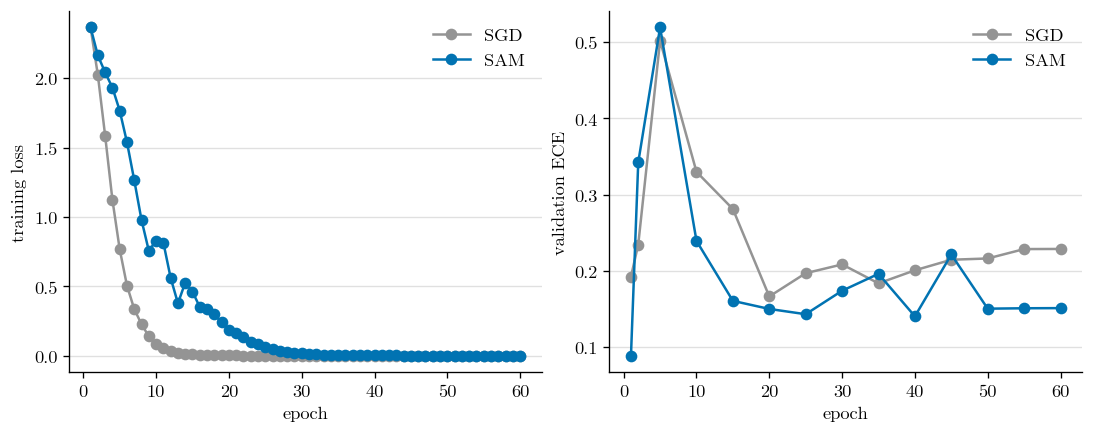

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for opt, key in [("sgd", "baseline"), ("sam", "method")]:
    recs = [r for r in per_epoch if r["optimizer"] == opt and r["seed"] == DEFAULT_SEEDS[0]]
    axes[0].plot([r["epoch"] for r in recs], [r["train_loss"] for r in recs],
                 marker="o", color=COLOURS[key], label=opt.upper())
    ev = [r for r in recs if r["val_ece"] is not None]
    axes[1].plot([r["epoch"] for r in ev], [r["val_ece"] for r in ev],
                 marker="o", color=COLOURS[key], label=opt.upper())
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].legend()
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation ECE"); axes[1].legend()
plt.show()

## Reading the results

At the demo scale (60 training examples, a few epochs) the printed numbers come from a tiny run. They show that the full pipeline
works and what each column means; they do not test the claim. The claim needs the original configuration: 50k training
images, 60 epochs and three seed pairs. With three seed pairs no test reaches conventional significance, so the comparison
is descriptive. The temperature-scaling column separates a global confidence shift (closed by a single temperature)
from a difference in the shape of the confidence, which only shows up as a gap that remains after scaling.